# Pemodelan XGBoost

Tahap ini menggunakan hasil preprocessing untuk melatih model XGBoost pada setiap saham. Model menghasilkan prediksi return hari bursa berikutnya yang digunakan untuk evaluasi dan pembentukan portofolio.

## Persiapan

Library, daftar hyperparameter, dan lokasi penyimpanan disiapkan sebelum training. Hasil tuning yang tersimpan digunakan sesuai pengaturan reuse_tuning.

In [1]:
# import library
import math
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import itertools
import time

import sys
# biar file .py di folder utama bisa di-import dari folder notebooks
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline_utils import show_table

from notebook_config import (
    blue,
    configure_notebook,
    feature_columns,
    orange,
    quarters_2025,
    random_seed,
    target,
    ticker_names,
    tickers,
)


In [2]:
# mengatur folder, grid hyperparameter, dan jumlah thread
root_dir, output_dir = configure_notebook()
processed_dir = root_dir / "data" / "processed"
output_dir = output_dir / "research"
output_dir.mkdir(parents=True, exist_ok=True)

model_dir = output_dir / "xgb_models"

model_dir.mkdir(parents=True, exist_ok=True)

# menetapkan urutan parameter pada tabel hasil tuning
parameter_columns = [
    "max_depth", "learning_rate", "n_estimators", "subsample",
    "colsample_bytree", "reg_alpha", "reg_lambda",
]

# menentukan nilai setiap parameter yang akan diuji pada validation set
# total ada 6.480 kombinasi per saham
grid_params = {
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "n_estimators": [50, 100, 150, 200],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0.0, 0.1, 1.0],
    "reg_lambda": [1.0, 2.0, 5.0],
}

# membatasi training saat tuning pada empat thread
tuning_jobs = 4

# menggunakan seluruh thread yang tersedia untuk training model kuartalan
training_jobs = -1

# melanjutkan pencarian untuk saham yang belum memiliki hasil tuning
# catatan: reuse_tuning sebenarnya tidak dipakai di sel lain
# yang menentukan tuning lanjut atau tidak itu file checkpoint
reuse_tuning = False

# menetapkan jumlah thread pada pengaturan global XGBoost
worker_threads = 6

xgb.set_config(nthread=worker_threads)

# merapikan nama parameter dan metrik pada tabel
display_names = {
    "Daily Predictions": "Prediksi per Saham",
    "Directional Accuracy (%)": "Directional Accuracy (%)",
    "Last Known Target Date": "Tanggal Target Training Terakhir",
    "Min Val RMSE (Raw)": "Minimum Validation RMSE",
    "Quarter": "Quarter",
    "Kuartal": "Quarter",
    "R2 Score": "R2 Score",
    "Selected Val RMSE": "Selected Validation RMSE",
    "Test Sample (Hari)": "Test Observations",
    "Ticker": "Ticker",
    "Train Observations": "Training Observations per Saham",
    "colsample_bytree": "Column Subsampling",
    "learning_rate": "Learning Rate",
    "max_depth": "Max Depth",
    "n_estimators": "Number of Estimators",
    "reg_alpha": "L1 Regularization",
    "reg_lambda": "L2 Regularization",
    "subsample": "Row Subsampling"
}


## Load Data

Fitur dan target dibaca dari panel_features.parquet. Kelengkapan kolom, daftar saham, dan duplikasi tanggal diperiksa sebelum data dibagi.

In [3]:
# membaca data fitur dan target dari notebook 02
feature_data = pd.read_parquet(processed_dir / "panel_features.parquet")
feature_data["snapshot_date"] = pd.to_datetime(feature_data["snapshot_date"])
feature_data["target_date"] = pd.to_datetime(feature_data["target_date"])

# mengecek kolom fitur, target, dan tanggal sebelum membagi data
required_columns = {"Kode Saham", "snapshot_date", "target_date", target, *feature_columns}
missing_columns = required_columns.difference(feature_data.columns)
if missing_columns:
    raise ValueError(f"Kolom wajib tidak tersedia: {sorted(missing_columns)}")

missing_tickers = sorted(set(tickers) - set(feature_data["Kode Saham"].unique()))
unexpected_tickers = sorted(set(feature_data["Kode Saham"].unique()) - set(tickers))
if missing_tickers or unexpected_tickers:
    raise ValueError(f"Feature dataset belum sesuai 11 saham. Hilang: {missing_tickers}; ekstra: {unexpected_tickers}. Jalankan Notebook 01 dan 02 dahulu.")
if feature_data.duplicated(["snapshot_date", "Kode Saham"]).any():
    raise ValueError('feature dataset memuat tanggal dan kode saham duplikat')

input_summary = pd.DataFrame({"Keterangan": ["Observasi", "Saham", "Tanggal keputusan awal", "Tanggal keputusan akhir"], "Nilai": [f"{len(feature_data):,}", str(feature_data["Kode Saham"].nunique()), str(feature_data["snapshot_date"].min().date()), str(feature_data["snapshot_date"].max().date())]})
show_table(input_summary, display_names=display_names)


,Keterangan,Nilai
0,Observasi,"15,543"
1,Saham,11
2,Tanggal keputusan awal,2020-02-18
3,Tanggal keputusan akhir,2025-12-29


## Pembagian Data

Data 2020 sampai 2023 digunakan untuk training, tahun 2024 untuk validation, dan tahun 2025 untuk testing. Tanggal target juga diperiksa agar return dari periode berikutnya tidak masuk ke training atau validation.

In [4]:
# membagi data berdasarkan waktu, tidak diacak
# training 2020 sampai 2023, validation 2024, test 2025
# target_date dibatasi supaya data tahun berikutnya tidak ikut terpakai
# memisahkan data menurut waktu dan mengecek batas tanggal target
# membatasi tanggal target agar tidak melewati periode training
base_train = feature_data[(feature_data["snapshot_date"] < "2024-01-01") & (feature_data["target_date"] < "2024-01-01")].copy()
validation = feature_data[feature_data["snapshot_date"].between("2024-01-01", "2024-12-31") & (feature_data["target_date"] < "2025-01-01")].copy()
out_of_sample_test = feature_data[feature_data["snapshot_date"].between("2025-01-01", "2025-12-31")].copy()

split_summary = pd.DataFrame([
    {
        "Dataset": 'Base Training',
        "Periode keputusan": "2020 sampai 2023",
        "Tanggal keputusan awal": base_train["snapshot_date"].min(),
        "Tanggal keputusan akhir": base_train["snapshot_date"].max(),
        "Observasi": len(base_train),
        "Observasi per saham": base_train.groupby("Kode Saham").size().min(),
        "Digunakan untuk": 'training kandidat hyperparameter',
    },
    {
        "Dataset": "Validation Set",
        "Periode keputusan": "2024",
        "Tanggal keputusan awal": validation["snapshot_date"].min(),
        "Tanggal keputusan akhir": validation["snapshot_date"].max(),
        "Observasi": len(validation),
        "Observasi per saham": validation.groupby("Kode Saham").size().min(),
        "Digunakan untuk": 'hyperparameter tuning',
    },
    {
        "Dataset": "Test Set",
        "Periode keputusan": "2025",
        "Tanggal keputusan awal": out_of_sample_test["snapshot_date"].min(),
        "Tanggal keputusan akhir": out_of_sample_test["snapshot_date"].max(),
        "Observasi": len(out_of_sample_test),
        "Observasi per saham": out_of_sample_test.groupby("Kode Saham").size().min(),
        "Digunakan untuk": "Prediksi dan evaluasi final",
    },
])

# memastikan periode training, validation, dan testing berurutan
assert base_train["snapshot_date"].max() < validation["snapshot_date"].min()
assert validation["snapshot_date"].max() < out_of_sample_test["snapshot_date"].min()
show_table(split_summary.set_index("Dataset"), display_names=display_names)


,Periode keputusan,Tanggal keputusan awal,Tanggal keputusan akhir,Observasi,Observasi per saham,Digunakan untuk
Dataset,,,,,,
Base Training,2020 sampai 2023,2020-02-18,2023-12-28,"10,340",940,training kandidat hyperparameter
Validation Set,2024,2024-01-02,2024-12-27,"2,596",236,hyperparameter tuning
Test Set,2025,2025-01-02,2025-12-29,"2,585",235,Prediksi dan evaluasi final


## Hyperparameter Tuning

Pencarian menguji 6.480 kombinasi parameter per saham menggunakan RMSE pada validation set. Kandidat dengan RMSE hingga 0,5% di atas nilai minimum dibandingkan berdasarkan skor kompleksitas, lalu dipilih kandidat dengan skor terendah.

Pada pengaturan saat ini, hasil tuning dibaca dari checkpoint, yaitu file hasil pencarian yang sudah disimpan. Pencarian dijalankan untuk saham yang belum memiliki hasil tuning jika reuse_tuning dinonaktifkan.

In [5]:
# membaca hasil tuning yang sudah tersimpan biar tidak tuning ulang dari awal
tuning_path = output_dir / "hyperparameter_tuning_results.csv"
checkpoint_path = processed_dir / "hyperparameter_tuning_checkpoint_11.csv"
# membaca hasil tuning tersimpan dengan mempertahankan presisi nilai desimal
tuning_record = pd.read_csv(checkpoint_path, float_precision="round_trip") if checkpoint_path.exists() else pd.DataFrame(columns=["Ticker"])

missing_tuning = [ticker for ticker in tickers if ticker not in set(tuning_record["Ticker"])]

In [6]:
# memproses pencarian hanya untuk saham yang belum memiliki hasil tuning
for ticker in missing_tuning:
    started = time.perf_counter()
    train_rows = base_train[base_train["Kode Saham"] == ticker]
    val_rows = validation[validation["Kode Saham"] == ticker]
    if train_rows.empty or val_rows.empty:
        raise ValueError(f"Training set atau validation set kosong untuk {ticker}")
    records = []
    # menguji seluruh kombinasi nilai pada grid parameter
    for values in itertools.product(*grid_params.values()):
        params = dict(zip(grid_params, values))
        # melatih kandidat dengan kombinasi parameter yang sedang diuji
        model = xgb.XGBRegressor(objective="reg:squarederror", random_state=random_seed, n_jobs=tuning_jobs, **params)
        model.fit(train_rows[feature_columns], train_rows[target])
        y_pred = model.predict(val_rows[feature_columns])
        records.append({"rmse_val": np.sqrt(mean_squared_error(val_rows[target], y_pred)), **params})

    candidates = pd.DataFrame(records).sort_values("rmse_val").reset_index(drop=True)
    min_rmse = candidates.loc[0, "rmse_val"]
    # mengambil kandidat dengan RMSE maksimal 0,5 persen di atas minimum
    eligible_candidates = candidates[candidates["rmse_val"] <= min_rmse * 1.005].copy()
    # memilih skor kompleksitas terendah dari kandidat yang memenuhi batas RMSE
    # skor kompleksitas: pohon makin dalam dan makin banyak, skornya makin besar
    # subsample di bawah 1 menambah skor, reg_lambda besar mengurangi skor
    eligible_candidates["complexity_score"] = (
        eligible_candidates["max_depth"] * 10 + eligible_candidates["n_estimators"] / 50
        + (1.0 - eligible_candidates["subsample"]) * 2 - eligible_candidates["reg_lambda"] * 0.1
    )
    selected = eligible_candidates.sort_values("complexity_score").iloc[0]
    record = {
        "Ticker": ticker,
        "Nama Bank": ticker_names[ticker],
        "Min Val RMSE (Raw)": min_rmse,
        "Selected Val RMSE": selected["rmse_val"],
        "Delta vs Min (%)": (selected["rmse_val"] / min_rmse - 1.0) * 100,
        **{column: selected[column] for column in parameter_columns},
        "Tuning Time (s)": time.perf_counter() - started,
    }
    tuning_record = pd.concat([tuning_record, pd.DataFrame([record])], ignore_index=True)
    available_order = [code for code in tickers if code in set(tuning_record["Ticker"])]
    tuning_record = tuning_record.set_index("Ticker").loc[available_order].reset_index()
    # menyimpan checkpoint setelah tuning satu saham selesai
    tuning_record.to_csv(checkpoint_path, index=False)


In [7]:
# menyimpan hyperparameter terbaik tiap saham, dipakai buat training per kuartal
if set(tuning_record["Ticker"]) != set(tickers):
    raise ValueError("Hasil tuning belum lengkap untuk 11 saham")
tuning_record = tuning_record.set_index("Ticker").loc[tickers].reset_index()
tuning_record.to_csv(tuning_path, index=False)
# menyesuaikan tipe parameter sebelum dipakai XGBoost
best_params_per_ticker = {}
for row in tuning_record.itertuples(index=False):
    best_params_per_ticker[row.Ticker] = {
        "max_depth": int(row.max_depth), "learning_rate": float(row.learning_rate),
        "n_estimators": int(row.n_estimators), "subsample": float(row.subsample),
        "colsample_bytree": float(row.colsample_bytree), "reg_alpha": float(row.reg_alpha),
        "reg_lambda": float(row.reg_lambda),
    }
# menyimpan parameter terpilih dan RMSE validation untuk setiap saham
locked_params = tuning_record[["Ticker", "Min Val RMSE (Raw)", "Selected Val RMSE", *parameter_columns]].copy()
locked_params.to_parquet(output_dir / "hyperparameter_tuning_results.parquet", index=False)
show_table(locked_params.set_index("Ticker").rename_axis("Emiten"), display_names=display_names)


,Minimum Validation RMSE,Selected Validation RMSE,Max Depth,Learning Rate,Number of Estimators,Row Subsampling,Column Subsampling,L1 Regularization,L2 Regularization
Emiten,,,,,,,,,
BBCA,0.0135798,0.0135798,4,0.1,100,0.7,0.7,0,1
BBNI,0.0189998,0.019041,2,0.01,50,1,0.8,0.1,5
BBRI,0.0182833,0.0183598,2,0.01,50,1,0.8,0.1,5
BBTN,0.0216848,0.0217517,2,0.05,50,1,0.7,1,5
BDMN,0.0099544,0.00998407,2,0.08,50,1,0.8,0,5
BJBR,0.0104542,0.0104651,2,0.01,50,1,1,0,5
BMRI,0.0191986,0.0192332,2,0.08,50,1,0.7,1,5
BNGA,0.0152433,0.0152986,2,0.1,50,1,0.8,1,5
BNLI,0.0324033,0.0324837,2,0.05,50,1,1,0,2


## Training dan Prediksi

Model dibangun pada awal setiap kuartal menggunakan parameter hasil tuning dan data dengan target yang sudah diketahui. Model tersebut digunakan untuk menghasilkan prediksi harian selama kuartal yang sama.

In [8]:
# training ulang tiap awal kuartal 2025
# model dilatih pakai semua data yang targetnya sudah diketahui
# lalu dipakai buat prediksi selama kuartal itu
# totalnya 11 saham x 4 kuartal = 44 model
prediction_frames = []
training_audit = []

for quarter in quarters_2025:
    quarter_start = pd.Timestamp(quarter["start"])
    quarter_end = pd.Timestamp(quarter["end"])

    for ticker in tickers:
        ticker_data = feature_data[feature_data["Kode Saham"] == ticker].sort_values("snapshot_date").copy()
        # menggunakan data dengan target yang sudah diketahui sebelum awal kuartal
        train_data = ticker_data[ticker_data["target_date"] < quarter_start].copy()
        test_data = ticker_data[
            ticker_data["snapshot_date"].between(quarter_start, quarter_end)
        ].copy()

        if train_data.empty or test_data.empty:
            raise ValueError(f"Training set atau test set kosong untuk {ticker} {quarter['name']}")
        if train_data["target_date"].max() >= quarter_start:
            raise AssertionError('Tanggal target melewati training cutoff quarterly')

        # melatih model kuartalan dengan parameter hasil tuning
        model = xgb.XGBRegressor(
            objective="reg:squarederror",
            random_state=random_seed,
            n_jobs=training_jobs,
            **best_params_per_ticker[ticker],
        )
        model.fit(train_data[feature_columns], train_data[target])
        model.save_model(model_dir / f"xgb_{ticker}_{quarter['code']}.json")

        # menggunakan model kuartal ini untuk memprediksi return hari berikutnya
        predicted = test_data.copy()
        predicted["y_pred"] = model.predict(test_data[feature_columns])
        predicted["quarter"] = quarter["name"]
        prediction_frames.append(predicted)

        training_audit.append({
            "Quarter": quarter["name"],
            "Ticker": ticker,
            "Train Observations": len(train_data),
            "Last Known Target Date": train_data["target_date"].max(),
            "Daily Predictions": len(test_data),
        })


## Simpan Hasil Prediksi

Hasil prediksi diperiksa agar setiap saham dan tanggal pada test set memiliki satu prediksi. Prediksi disimpan ke predictions_2025.parquet, sedangkan jumlah data training dan batas tanggal target dirangkum per kuartal.

In [9]:
# menggabungkan prediksi 4 kuartal, mengecek lengkap atau belum, lalu menyimpan
predictions_2025 = pd.concat(prediction_frames, ignore_index=True)
predictions_2025 = predictions_2025.sort_values(["snapshot_date", "Kode Saham"]).reset_index(drop=True)
# memastikan setiap saham dan tanggal pada test set memiliki satu prediksi
expected_pairs = pd.MultiIndex.from_frame(out_of_sample_test[["snapshot_date", "Kode Saham"]])
actual_pairs = pd.MultiIndex.from_frame(predictions_2025[["snapshot_date", "Kode Saham"]])
if not actual_pairs.is_unique or len(actual_pairs) != len(expected_pairs) or not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError("Prediksi 2025 belum sesuai observasi feature dataset")
if len(training_audit) != len(tickers) * len(quarters_2025):
    raise ValueError('Jumlah quarterly model tidak sesuai 11 x 4')
predictions_2025.to_parquet(processed_dir / "predictions_2025.parquet", index=False)

training_audit_df = pd.DataFrame(training_audit)
training_audit_df.to_parquet(output_dir / "quarterly_retraining_audit_2025.parquet", index=False)

# meringkas jumlah model dan data yang digunakan pada setiap kuartal
training_summary = training_audit_df.groupby("Quarter", sort=False).agg({
    "Ticker": "nunique", "Train Observations": "first", "Last Known Target Date": "first", "Daily Predictions": "first"
}).rename(columns={"Ticker": "Jumlah model"})
show_table(training_summary.rename_axis("Kuartal"), display_names=display_names)


,Jumlah model,Training Observations per Saham,Tanggal Target Training Terakhir,Prediksi per Saham
Quarter,,,,
Q1 2025,11,"1,177",2024-12-30,58
Q2 2025,11,"1,235",2025-03-27,51
Q3 2025,11,"1,286",2025-06-30,64
Q4 2025,11,"1,350",2025-09-30,62


## Evaluasi Model

Prediksi dibandingkan dengan return aktual menggunakan RMSE, MAE, R2, dan Directional Accuracy. Untuk Directional Accuracy, arah return dibedakan menjadi positif, negatif, dan nol.

In [10]:
# RMSE dan MAE itu rata-rata besar error, makin kecil makin bagus
# R2 itu seberapa banyak variasi return yang bisa dijelaskan model
# Directional Accuracy itu persen hari yang arah naik turunnya tertebak benar
# menghitung metrik dari prediksi harian selama 2025
evaluation_records = []
for ticker in tickers:
    ticker_predictions = predictions_2025[predictions_2025["Kode Saham"] == ticker]
    actual = ticker_predictions[target]
    predicted = ticker_predictions["y_pred"]
    evaluation_records.append({
        "Ticker": ticker,
        "Nama Bank": ticker_names[ticker],
        "Test Sample (Hari)": len(ticker_predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "R2 Score": r2_score(actual, predicted),
        # membandingkan arah positif, negatif, atau nol pada return aktual dan prediksi
        "Directional Accuracy (%)": np.mean(np.sign(actual) == np.sign(predicted)) * 100.0,
    })

evaluation_2025 = pd.DataFrame(evaluation_records)
evaluation_2025.to_parquet(output_dir / "evaluation_metrics_2025.parquet", index=False)
show_table(evaluation_2025.set_index("Ticker").rename_axis("Emiten"), display_names=display_names)


,Nama Bank,Test Observations,RMSE,MAE,R2 Score,Directional Accuracy (%)
Emiten,,,,,,
BBCA,Bank Central Asia Tbk,235,0.0200953,0.0150639,-0.183465,48.0851
BBNI,Bank Negara Indonesia Tbk,235,0.0241155,0.0170789,-0.004666,43.8298
BBRI,Bank Rakyat Indonesia Tbk,235,0.0234089,0.0167887,-0.000619141,48.5106
BBTN,Bank Tabungan Negara Tbk,235,0.0286465,0.0207669,-0.00409782,34.8936
BDMN,Bank Danamon Indonesia Tbk,235,0.0104031,0.00725415,-0.00369745,40.4255
BJBR,Bank Pembangunan Daerah Jawa Barat dan Banten Tbk,235,0.0160209,0.00935359,-0.00194978,37.4468
BMRI,Bank Mandiri Tbk,235,0.023583,0.0165991,-0.00107314,43.4043
BNGA,Bank CIMB Niaga Tbk,235,0.012318,0.00803717,-0.00312062,40
BNLI,Bank Permata Tbk,235,0.0384608,0.0264455,-0.0547012,47.6596


## Perbandingan RMSE Validasi dengan Uji

In [11]:
# fitur yang nilainya ikut level harga, dicek keluar dari rentang data latih atau tidak
# membandingkan RMSE test 2025 dengan RMSE validasi 2024
# sama dua pembanding sederhana: menebak nol terus dan rata-rata return historis
price_level_features = ["SMA10", "SMA20", "EMA10", "BB_Upper", "BB_Lower"]
selected_val_rmse = tuning_record.set_index("Ticker")["Selected Val RMSE"]

rmse_context, direction_context = [], []
for ticker in tickers:
    ticker_predictions = predictions_2025[predictions_2025["Kode Saham"] == ticker].sort_values("snapshot_date")
    ticker_features = feature_data[feature_data["Kode Saham"] == ticker]
    actual = ticker_predictions[target].to_numpy()
    predicted = ticker_predictions["y_pred"].to_numpy()

    # baseline rata-rata historis dan mengecek rentang fitur memakai batas data latih tiap kuartal
    mean_baseline = np.full(len(ticker_predictions), np.nan)
    outside_range = np.zeros(len(ticker_predictions), dtype=bool)
    for quarter in quarters_2025:
        quarter_start, quarter_end = pd.Timestamp(quarter["start"]), pd.Timestamp(quarter["end"])
        train_rows = ticker_features[ticker_features["target_date"] < quarter_start]
        in_quarter = ticker_predictions["snapshot_date"].between(quarter_start, quarter_end).to_numpy()
        mean_baseline[in_quarter] = train_rows[target].mean()
        quarter_rows = ticker_predictions.loc[in_quarter, price_level_features]
        low, high = train_rows[price_level_features].min(), train_rows[price_level_features].max()
        outside_range[in_quarter] = ((quarter_rows < low) | (quarter_rows > high)).any(axis=1).to_numpy()
    if np.isnan(mean_baseline).any():
        raise ValueError(f"Baseline rata-rata belum terisi untuk {ticker}")

    # RMSE model dibandingkan sama tebakan nol dan rata-rata historis
    rmse_test = np.sqrt(np.mean((actual - predicted) ** 2))
    rmse_val = selected_val_rmse[ticker]
    rmse_context.append({
        "Ticker": ticker,
        "RMSE Validasi 2024": rmse_val,
        "RMSE Uji 2025": rmse_test,
        "Perubahan RMSE (%)": (rmse_test - rmse_val) / rmse_val * 100,
        "RMSE Prediksi Nol": np.sqrt(np.mean(actual ** 2)),
        "RMSE Rata-rata Historis": np.sqrt(np.mean((actual - mean_baseline) ** 2)),
        "SD Return 2024": validation.loc[validation["Kode Saham"] == ticker, target].std(),
        "SD Return 2025": actual.std(ddof=1),
    })

    # statistik arah return: hari nol, naik, turun, dan akurasi arah tanpa hari nol
    non_zero = actual != 0
    direction_context.append({
        "Ticker": ticker,
        "Return Nol (%)": (~non_zero).mean() * 100,
        "Hari Naik (%)": (actual > 0).mean() * 100,
        "Hari Turun (%)": (actual < 0).mean() * 100,
        "Prediksi Positif (%)": (predicted > 0).mean() * 100,
        "Directional Accuracy (%)": np.mean(np.sign(actual) == np.sign(predicted)) * 100,
        "DA Tanpa Return Nol (%)": np.mean(np.sign(actual[non_zero]) == np.sign(predicted[non_zero])) * 100,
        "Rasio SD Prediksi/Aktual": predicted.std(ddof=1) / actual.std(ddof=1),
        "Hari Fitur Harga di Luar Rentang Latih (%)": outside_range.mean() * 100,
    })

rmse_context_2025 = pd.DataFrame(rmse_context)
direction_context_2025 = pd.DataFrame(direction_context)
rmse_context_2025.to_csv(output_dir / "evaluation_rmse_context_2025.csv", index=False)
direction_context_2025.to_csv(output_dir / "evaluation_direction_context_2025.csv", index=False)

display(rmse_context_2025.set_index("Ticker").round(6))
display(direction_context_2025.set_index("Ticker").round(2))

,RMSE Validasi 2024,RMSE Uji 2025,Perubahan RMSE (%),RMSE Prediksi Nol,RMSE Rata-rata Historis,SD Return 2024,SD Return 2025
Ticker,,,,,,,
BBCA,0.01358,0.020095,47.9786,0.018485,0.018509,0.014002,0.018512
BBNI,0.019041,0.024116,26.6502,0.02406,0.024061,0.019106,0.024111
BBRI,0.01836,0.023409,27.5005,0.023404,0.023407,0.018409,0.023452
BBTN,0.021752,0.028647,31.6978,0.02859,0.028602,0.021776,0.028649
BDMN,0.009984,0.010403,4.19685,0.010386,0.010386,0.010087,0.010406
BJBR,0.010465,0.016021,53.0894,0.016012,0.016016,0.010435,0.016039
BMRI,0.019233,0.023583,22.616,0.023572,0.023589,0.019256,0.023621
BNGA,0.015299,0.012318,-19.4829,0.012299,0.012318,0.015311,0.012325
BNLI,0.032484,0.038461,18.4002,0.038257,0.038149,0.032972,0.03753


,Return Nol (%),Hari Naik (%),Hari Turun (%),Prediksi Positif (%),Directional Accuracy (%),DA Tanpa Return Nol (%),Rasio SD Prediksi/Aktual,Hari Fitur Harga di Luar Rentang Latih (%)
Ticker,,,,,,,,
BBCA,8.09,41.28,50.64,55.32,48.09,52.31,0.48,0
BBNI,8.09,39.15,52.77,48.94,43.83,47.69,0.03,0
BBRI,5.11,44.68,50.21,60,48.51,51.12,0.03,0
BBTN,9.79,34.89,55.32,100,34.89,38.68,0.02,0.43
BDMN,19.15,40.43,40.43,99.15,40.43,50,0.08,0
BJBR,29.79,33.62,36.6,36.6,37.45,53.33,0.14,11.91
BMRI,5.53,43.4,51.06,100,43.4,45.95,0.01,0
BNGA,14.47,40,45.53,100,40,46.77,0,0
BNLI,10.64,49.36,40,54.47,47.66,53.33,0.53,45.11


## Perbandingan Prediksi dan Return Aktual

Grafik menampilkan prediksi dan return aktual pada tanggal target masing-masing saham. Grafik berikutnya membandingkan RMSE, MAE, dan Directional Accuracy antar saham.

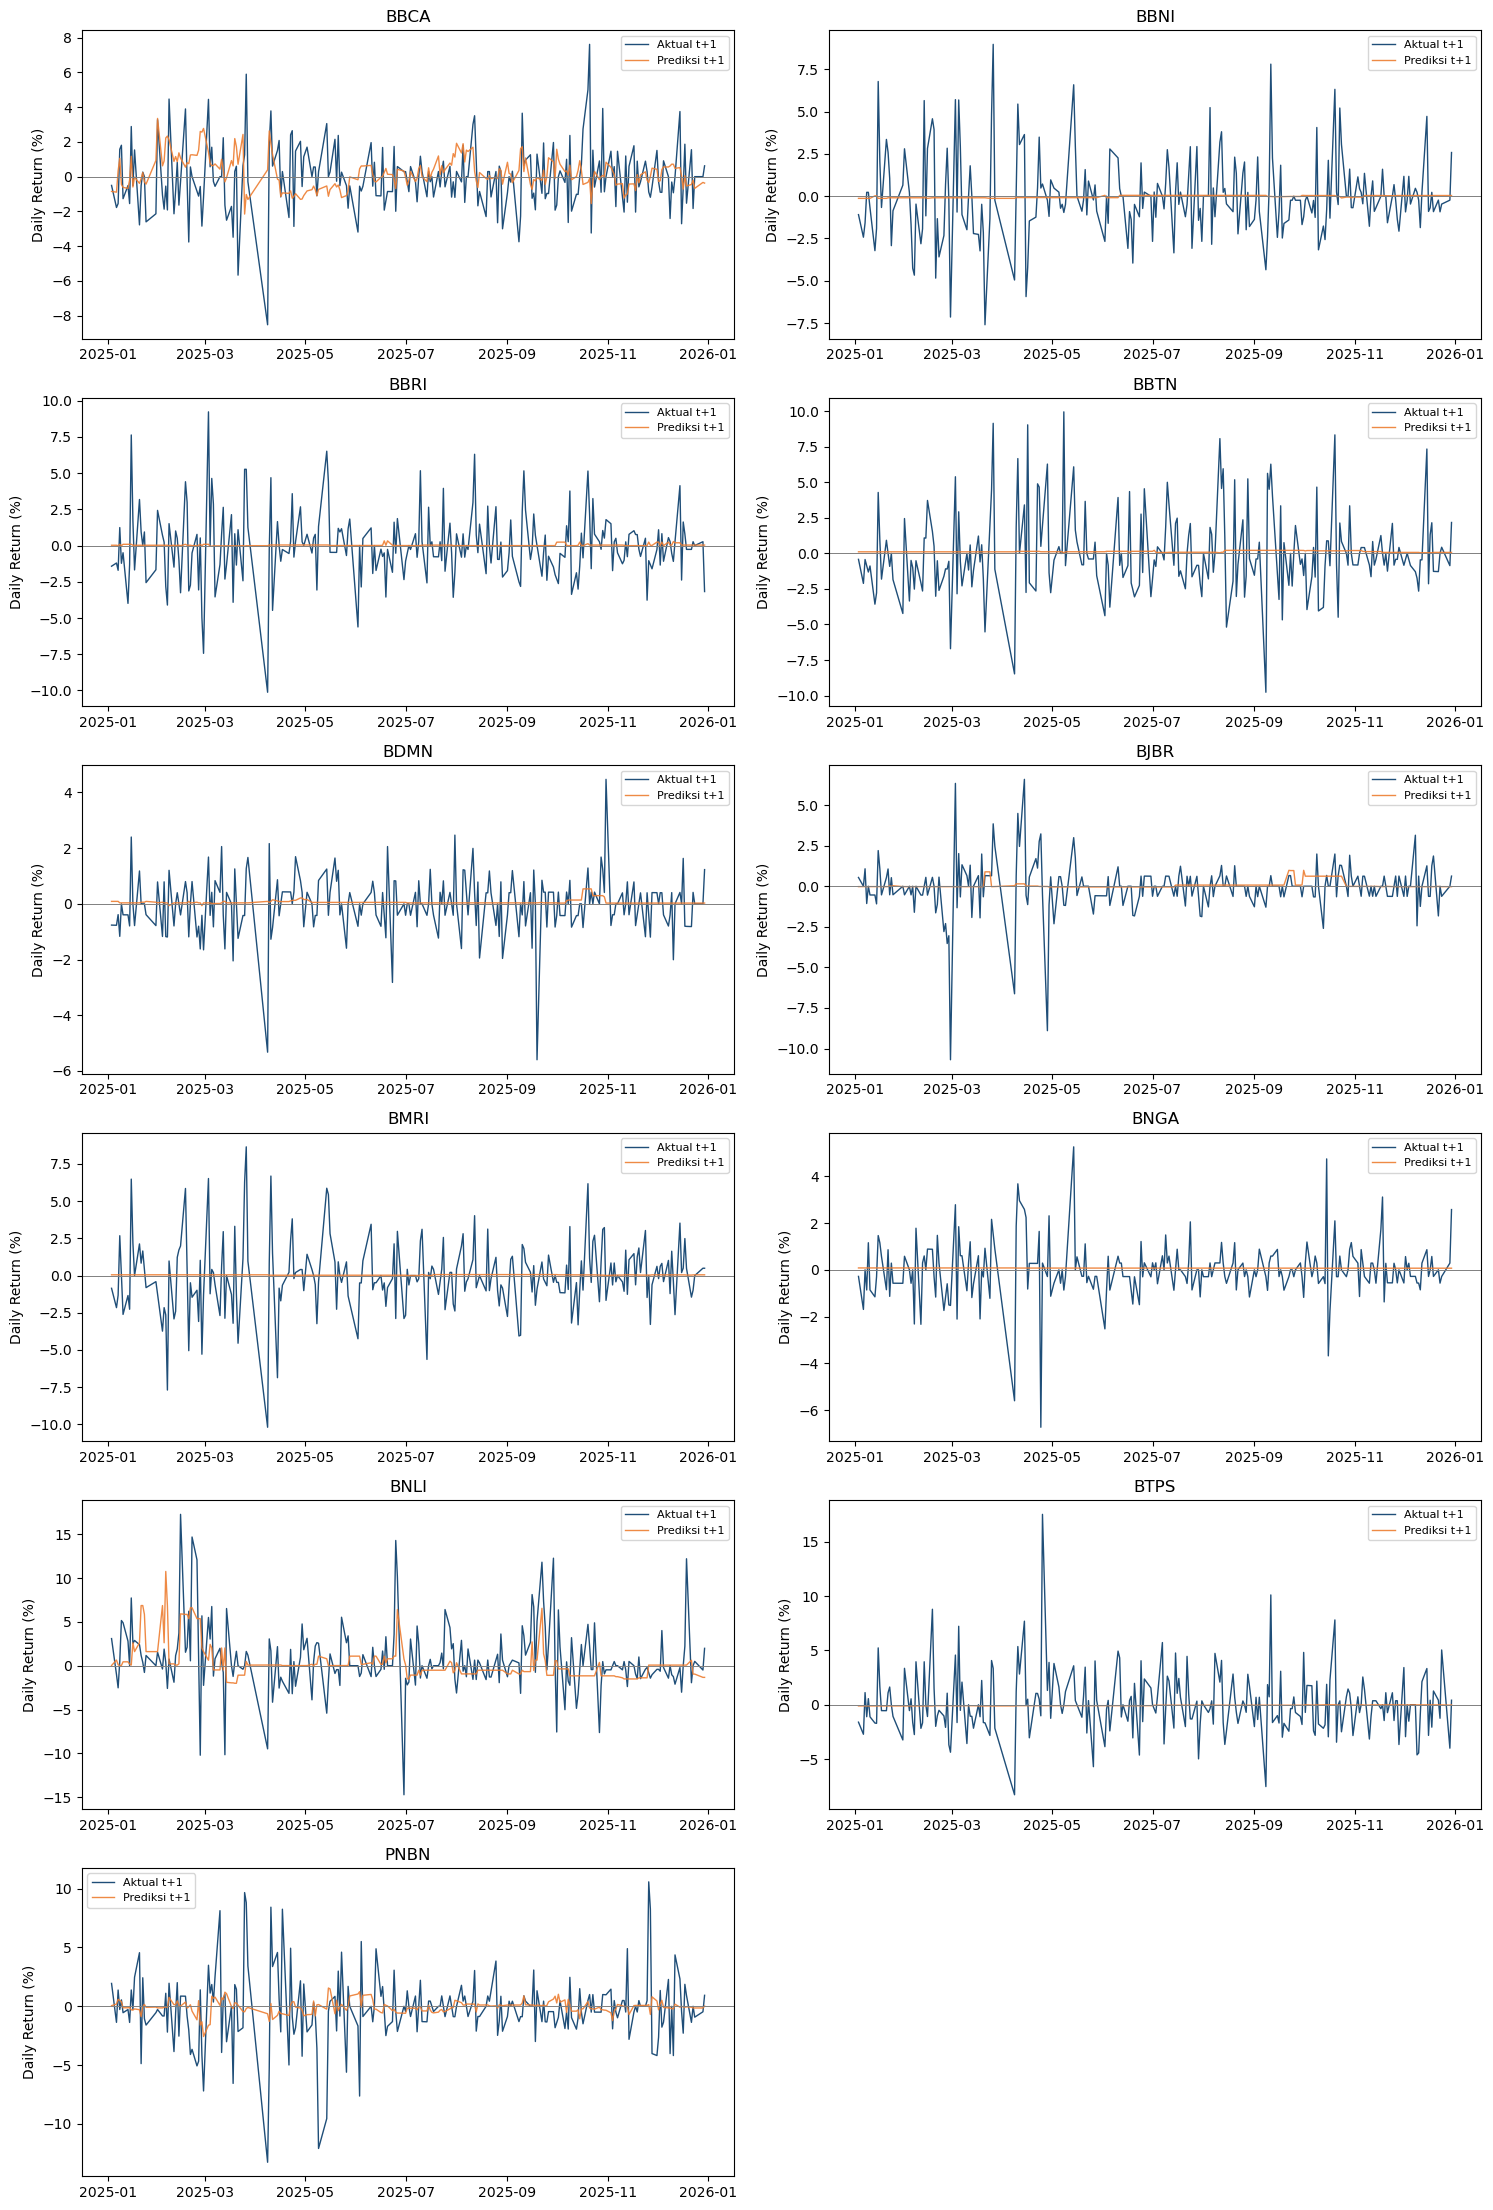

In [12]:
# grafik return aktual dan prediksi tiap saham selama 2025
# menampilkan prediksi dan return aktual pada tanggal target yang sama
fig, axes = plt.subplots(math.ceil(len(tickers) / 2), 2, figsize=(15, 3.7 * math.ceil(len(tickers) / 2)), sharex=False)
for axis, ticker in zip(axes.flat, tickers):
    ticker_predictions = predictions_2025[predictions_2025["Kode Saham"] == ticker]
    axis.plot(ticker_predictions["target_date"], ticker_predictions[target] * 100, color=blue, linewidth=1.0, label="Aktual t+1")
    axis.plot(ticker_predictions["target_date"], ticker_predictions["y_pred"] * 100, color=orange, linewidth=1.0, alpha=0.9, label="Prediksi t+1")
    axis.axhline(0, color="gray", linewidth=0.7)
    axis.set_title(ticker)
    axis.set_ylabel('Daily Return (%)')
    axis.legend(fontsize=8)
for unused_axis in axes.flat[len(tickers):]:
    unused_axis.set_visible(False)
# fig.suptitle("Prediksi dan Return Aktual Hari Berikutnya pada 2025", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

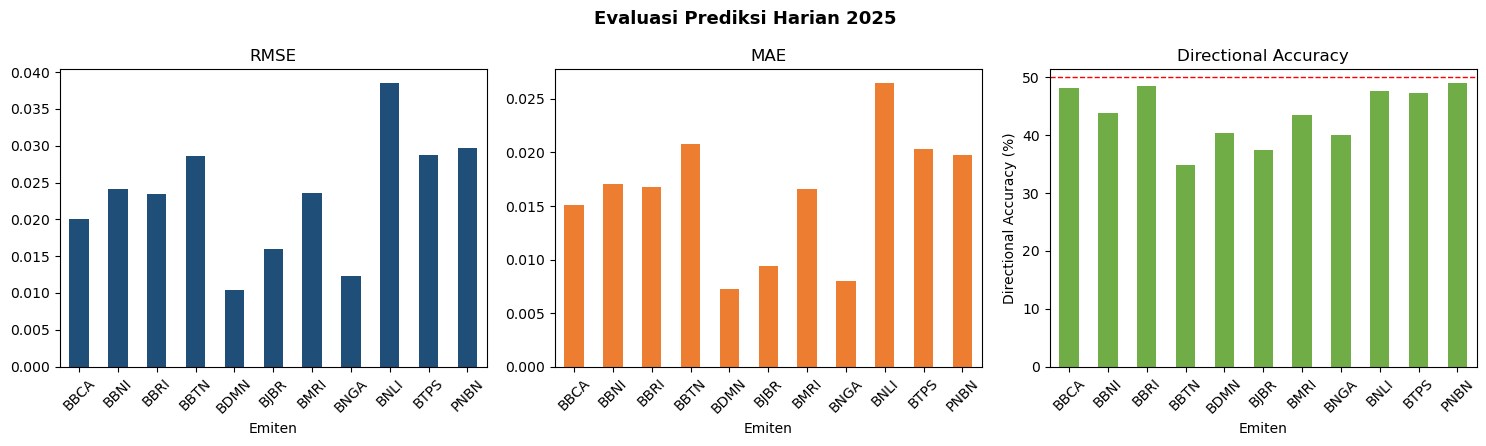

In [13]:
# membandingkan metrik evaluasi antar saham
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
evaluation_2025.plot.bar(x="Ticker", y="RMSE", ax=axes[0], color=blue, legend=False, title="RMSE")
evaluation_2025.plot.bar(x="Ticker", y="MAE", ax=axes[1], color=orange, legend=False, title="MAE")
evaluation_2025.plot.bar(x="Ticker", y="Directional Accuracy (%)", ax=axes[2], color="#70AD47", legend=False, title='Directional Accuracy')
axes[2].set_ylabel('Directional Accuracy (%)')
axes[2].axhline(50, color="red", linestyle="--", linewidth=1)
for axis in axes:
    axis.tick_params(axis="x", rotation=45)
    axis.set_xlabel("Emiten")
fig.suptitle("Evaluasi Prediksi Harian 2025", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()
